In [11]:
#Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sys
import os
import seaborn as sns
from sklearn.decomposition import PCA
from joblib import dump, load
from collections import defaultdict
from matplotlib.gridspec import GridSpec
from pathlib import Path


# Add the 'src' directory to the system path
src_dir = os.path.abspath(os.path.join(os.getcwd(), "src"))
sys.path.insert(0, src_dir)

#import the module
import corr_utils
from scipy.stats import skew, kurtosis, ks_2samp
from sklearn.metrics import silhouette_samples, silhouette_score



## Datasets

In [12]:
# Load the full pearson correlation matrix P-G
pearson = load('data/full_pearson100.joblib')
pearson


,A1BG,A1BG-AS1,A1CF,A2M,A2M-AS1,A2ML1,A2ML1-AS1,A2ML1-AS2,A2MP1,A3GALT2,...,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11A,ZYG11AP1,ZYG11B,ZYX,ZZEF1,ZZZ3
proteins,,,,,,,,,,,,,,,,,,,,,
A2M,0.246571,0.207437,0.000000,0.365397,0.000000,0.000000,0.0,0.0,0.0,0.166604,...,0.000000,0.000000,0.000000,0.000000,0.0,0.070655,0.206545,0.176568,0.000000,0.000000
AAAS,0.000000,0.000000,0.000000,0.000000,0.089634,0.000000,0.0,0.0,0.0,0.000000,...,-0.098537,0.000000,0.000000,0.000000,0.0,-0.074209,0.000000,0.126028,-0.140422,0.124015
AACS,0.000000,0.000000,0.086278,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000
AAGAB,0.095826,0.106925,0.000000,0.000000,0.000000,-0.147446,0.0,0.0,0.0,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,-0.108280,0.235286,0.000000
AAK1,0.141985,0.129458,-0.118349,0.098589,0.094037,-0.076360,0.0,0.0,0.0,0.094948,...,0.148686,0.104587,0.101981,0.000000,0.0,0.000000,0.275717,0.300802,0.000000,0.118403
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZRANB2,0.000000,0.000000,-0.104882,0.000000,-0.075800,0.000000,0.0,0.0,0.0,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,-0.195975,0.000000,0.186568
ZW10,0.000000,0.000000,0.000000,0.000000,0.148775,0.000000,0.0,0.0,0.0,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.125551,0.000000,0.000000
ZWILCH,0.000000,0.000000,0.000000,0.000000,0.000000,-0.164620,0.0,0.0,0.0,0.000000,...,0.157618,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.157165,0.106069


In [13]:

transcriptomics_filtered = load('data/transcriptomics_filtered.joblib')
transcriptomics_filtered

genes,A1BG,A1BG-AS1,A1CF,A2M,A2ML1,A4GALT,AAAS,AACS,AACSP1,AADAC,...,ZWILCH,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11A,ZYG11B,ZYX,ZZEF1,ZZZ3
samples,,,,,,,,,,,,,,,,,,,,,
MDAMB468_BREAST,2.689299,2.954196,0.014355,3.329124,0.443607,1.575312,5.311430,4.531069,0.056584,0.124328,...,4.139142,6.986752,2.192194,3.114367,4.250962,2.792855,3.250962,6.233811,3.512227,5.221490
SH4_SKIN,4.980025,3.583760,0.000000,8.405099,0.000000,0.111031,5.229972,4.095924,0.070389,0.014355,...,3.698218,6.113742,1.384050,2.659925,4.979111,0.014355,2.553361,6.644000,3.659925,4.249445
AU565_BREAST,2.518535,2.269033,0.014355,1.275007,2.451541,0.933573,6.011898,5.564378,1.618239,0.250962,...,4.235727,7.373909,0.632268,2.049631,3.471187,0.014355,2.794936,7.776828,3.814550,3.978196
KMRC1_KIDNEY,0.084064,0.070389,0.000000,0.137504,0.000000,2.903038,4.842476,3.357552,0.056584,0.124328,...,4.584361,6.704734,0.432959,1.021480,1.475085,0.485427,1.384050,5.510962,1.263034,3.416840
CAL51_BREAST,4.729553,2.807355,0.014355,0.575312,0.713696,3.751678,6.262847,3.874797,0.056584,0.070389,...,4.835924,7.356496,1.700440,2.424922,3.884598,0.084064,3.558268,6.812113,4.068671,4.939697
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
FADU_UPPER_AERODIGESTIVE_TRACT,0.070389,0.389567,0.028569,0.028569,0.263034,4.168321,5.244887,5.409391,0.189034,2.446256,...,4.865919,7.543882,0.014355,0.028569,3.807355,0.790772,3.247928,5.279471,4.277241,5.158660
KP4_PANCREAS,0.389567,0.632268,0.042644,0.367371,0.150560,2.163499,6.280585,4.335569,0.014355,4.980939,...,5.210233,6.656067,2.137504,2.558268,3.754888,0.042644,2.912650,6.915401,3.799087,4.475085
MONOMAC6_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,3.945795,2.185867,0.014355,0.000000,0.070389,0.042644,5.667608,3.218781,0.056584,0.000000,...,4.143230,7.929318,1.137504,1.835924,4.955127,0.056584,2.107688,5.816856,3.693766,5.030777


In [14]:
#Remove genes filtered out in the filtering procedure
pearson = pearson[transcriptomics_filtered.columns]
pearson

,A1BG,A1BG-AS1,A1CF,A2M,A2ML1,A4GALT,AAAS,AACS,AACSP1,AADAC,...,ZWILCH,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11A,ZYG11B,ZYX,ZZEF1,ZZZ3
proteins,,,,,,,,,,,,,,,,,,,,,
A2M,0.246571,0.207437,0.000000,0.365397,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,...,0.124962,0.000000,0.000000,0.000000,0.000000,0.0,0.206545,0.176568,0.000000,0.000000
AAAS,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.160298,0.0,0.000000,...,-0.078537,-0.098537,0.000000,0.000000,0.000000,0.0,0.000000,0.126028,-0.140422,0.124015
AACS,0.000000,0.000000,0.086278,0.000000,0.000000,-0.113664,0.000000,0.470513,0.0,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000
AAGAB,0.095826,0.106925,0.000000,0.000000,-0.147446,-0.121553,0.168963,0.000000,0.0,0.000000,...,0.191555,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,-0.108280,0.235286,0.000000
AAK1,0.141985,0.129458,-0.118349,0.098589,-0.076360,0.000000,0.000000,0.000000,0.0,-0.133701,...,0.092193,0.148686,0.104587,0.101981,0.000000,0.0,0.275717,0.300802,0.000000,0.118403
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZRANB2,0.000000,0.000000,-0.104882,0.000000,0.000000,-0.156288,0.190009,0.000000,0.0,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,-0.195975,0.000000,0.186568
ZW10,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.125551,0.000000,0.000000
ZWILCH,0.000000,0.000000,0.000000,0.000000,-0.164620,-0.119140,0.155437,0.000000,0.0,0.000000,...,0.222471,0.157618,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.157165,0.106069


## Cluster Overlap

In [15]:

# --- Configuration ---
PG_DIR = 'results/clusters_pg'
PP_DIR = 'results/clusters_pp'
PE_DIR = 'results/clusters_pe'
RESULTS_DIR = Path('results/overlap_analysis')
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# --- Read cluster files once ---
pg_clusters = corr_utils.read_cluster_files(PG_DIR)
pp_clusters = corr_utils.read_cluster_files(PP_DIR)
pe_clusters = corr_utils.read_cluster_files(PE_DIR)

# --- Common k values ---
common_k_values = sorted(set(pg_clusters.keys()) & set(pp_clusters.keys()) & set(pe_clusters.keys()))
if not common_k_values:
    print("No common k values found across all three clustering methods!")
else:
    print(f"Common k values found: {common_k_values}")

    # Container for all results so we don't recompute
    results = {}

    # --- Compute pairwise overlaps + consensus once per k and save outputs ---
    for k in common_k_values:
        print(f"\nAnalyzing clusters for k={k}...")

        pg_df = pg_clusters[k]
        pp_df = pp_clusters[k]
        pe_df = pe_clusters[k]

        # Pairwise overlaps (count, percentage, contingency)
        pg_pp_count, pg_pp_pct, pg_pp_cont = corr_utils.compute_overlap(
            pg_df, pp_df,
            df1_name=f"PG_k{k}",
            df2_name=f"PP_k{k}",
            output_file=str(RESULTS_DIR / f"PG_PP_k{k}_overlap.csv")
        )
        pp_pe_count, pp_pe_pct, pp_pe_cont = corr_utils.compute_overlap(
            pp_df, pe_df,
            df1_name=f"PP_k{k}",
            df2_name=f"PE_k{k}",
            output_file=str(RESULTS_DIR / f"PP_PE_k{k}_overlap.csv")
        )
        pg_pe_count, pg_pe_pct, pg_pe_cont = corr_utils.compute_overlap(
            pg_df, pe_df,
            df1_name=f"PG_k{k}",
            df2_name=f"PE_k{k}",
            output_file=str(RESULTS_DIR / f"PG_PE_k{k}_overlap.csv")
        )

        # Save contingency tables
        pg_pp_cont.to_csv(RESULTS_DIR / f"PG_PP_k{k}_contingency.csv")
        pp_pe_cont.to_csv(RESULTS_DIR / f"PP_PE_k{k}_contingency.csv")
        pg_pe_cont.to_csv(RESULTS_DIR / f"PG_PE_k{k}_contingency.csv")

        # Consensus across all three
        consensus = corr_utils.compute_consensus(pg_df, pp_df, pe_df)

        # Store once; re-use for summary & plots
        results[k] = {
            'pg_pp_count': pg_pp_count, 'pg_pp_pct': pg_pp_pct, 'cont_pg_pp': pg_pp_cont,
            'pp_pe_count': pp_pe_count, 'pp_pe_pct': pp_pe_pct, 'cont_pp_pe': pp_pe_cont,
            'pg_pe_count': pg_pe_count, 'pg_pe_pct': pg_pe_pct, 'cont_pg_pe': pg_pe_cont,
            'consensus': consensus,
            # Keep cluster dfs for plotting distributions
            'pg_df': pg_df, 'pp_df': pp_df, 'pe_df': pe_df
        }

        # Console summary for this k
        print(f"Overlap (k={k}): "
              f"PG–PP {pg_pp_count} ({pg_pp_pct:.2f}%), "
              f"PP–PE {pp_pe_count} ({pp_pe_pct:.2f}%), "
              f"PG–PE {pg_pe_count} ({pg_pe_pct:.2f}%).")
        print(f"Full consensus count: {consensus.get('full_consensus_count', 'NA')} "
              f"({consensus.get('all_consensus', 0):.2f}% of total).")

    # --- Summary CSV (counts + percentages + consensus) ---
    summary_rows = []
    for k in common_k_values:
        r = results[k]
        c = r['consensus']
        summary_rows.append({
            'k': k,
            'PG_PP_overlap_count': r['pg_pp_count'],
            'PG_PP_overlap_pct': r['pg_pp_pct'],
            'PP_PE_overlap_count': r['pp_pe_count'],
            'PP_PE_overlap_pct': r['pp_pe_pct'],
            'PG_PE_overlap_count': r['pg_pe_count'],
            'PG_PE_overlap_pct': r['pg_pe_pct'],
            'Full_consensus_count': c.get('full_consensus_count', np.nan),
            'Full_consensus_pct': c.get('all_consensus', np.nan),
            'Total_proteins': c.get('total_proteins', np.nan),
            # (optional) keep the pairwise consensus pcts if your function returns them
            'Pairwise_pg_pp_consensus_pct': c.get('pg_pp_overlap', np.nan),
            'Pairwise_pp_pe_consensus_pct': c.get('pp_pe_overlap', np.nan),
            'Pairwise_pg_pe_consensus_pct': c.get('pg_pe_overlap', np.nan),
        })
    summary_df = pd.DataFrame(summary_rows)
    summary_path = RESULTS_DIR / "overlap_summary.csv"
    summary_df.to_csv(summary_path, index=False)
    print(f"\nOverlap summary saved to {summary_path}")

    # --- Visualization per k: distributions + pairwise heatmaps (2x2 grid) ---
    for k in common_k_values:
        r = results[k]
        pg_df, pp_df, pe_df = r['pg_df'], r['pp_df'], r['pe_df']

        fig = plt.figure(figsize=(20, 15))
        gs = GridSpec(2, 2, figure=fig)

        # Grid 1: Cluster distributions (normalized to %)
        ax1 = fig.add_subplot(gs[0, 0])

        def cluster_pct(df, k_val):
            counts = (df['Cluster']
                      .value_counts()
                      .sort_index()
                      .reindex(range(1, int(k_val) + 1), fill_value=0))
            total = counts.sum()
            return (counts / total * 100) if total else counts.astype(float)

        pg_pct = cluster_pct(pg_df, k)
        pp_pct = cluster_pct(pp_df, k)
        pe_pct = cluster_pct(pe_df, k)

        bar_width = 0.25
        idx = np.arange(1, int(k) + 1)

        ax1.bar(idx - bar_width, pg_pct.values, width=bar_width, label='PG')
        ax1.bar(idx,               pp_pct.values, width=bar_width, label='PP')
        ax1.bar(idx + bar_width,   pe_pct.values, width=bar_width, label='PE')

        ax1.set_xlabel('Cluster Number')
        ax1.set_ylabel('Percentage of Proteins')
        ax1.set_title(f'Cluster Distributions for k={k}')
        ax1.set_xticks(idx)
        ax1.legend()

        # Grid 2: PG vs PP heatmap
        ax2 = fig.add_subplot(gs[0, 1])
        sns.heatmap(r['cont_pg_pp'].astype(int), annot=True, cmap='viridis', fmt='d', ax=ax2)
        ax2.set_title(f'PG vs PP (Overlap: {r["pg_pp_count"]} proteins, {r["pg_pp_pct"]:.2f}%)')
        ax2.set_xlabel('PP Clusters')
        ax2.set_ylabel('PG Clusters')

        # Grid 3: PP vs PE heatmap
        ax3 = fig.add_subplot(gs[1, 0])
        sns.heatmap(r['cont_pp_pe'].astype(int), annot=True, cmap='viridis', fmt='d', ax=ax3)
        ax3.set_title(f'PP vs PE (Overlap: {r["pp_pe_count"]} proteins, {r["pp_pe_pct"]:.2f}%)')
        ax3.set_xlabel('PE Clusters')
        ax3.set_ylabel('PP Clusters')

        # Grid 4: PG vs PE heatmap
        ax4 = fig.add_subplot(gs[1, 1])
        sns.heatmap(r['cont_pg_pe'].astype(int), annot=True, cmap='viridis', fmt='d', ax=ax4)
        ax4.set_title(f'PG vs PE (Overlap: {r["pg_pe_count"]} proteins, {r["pg_pe_pct"]:.2f}%)')
        ax4.set_xlabel('PE Clusters')
        ax4.set_ylabel('PG Clusters')

        plt.tight_layout()
        out_grid = RESULTS_DIR / f'cluster_comparison_k{k}.png'
        plt.savefig(out_grid, dpi=300)
        plt.close()
        print(f"Saved {out_grid}")

        # --- Consensus bar chart ---
        c = r['consensus']
        labels = ['PG–PP', 'PP–PE', 'PG–PE', 'All Three']
        vals = [
            c.get('pg_pp_overlap', np.nan),
            c.get('pp_pe_overlap', np.nan),
            c.get('pg_pe_overlap', np.nan),
            c.get('all_consensus', np.nan)
        ]

        plt.figure(figsize=(10, 8))
        plt.bar(labels, vals)
        plt.ylabel('Percentage of Proteins')
        plt.title(f'Clustering Consensus (k={k})')
        plt.ylim(0, 100)

        for i, v in enumerate(vals):
            if pd.notna(v):
                plt.text(i, min(v + 1, 99.5), f'{v:.2f}%', ha='center', va='bottom')

        total_proteins = c.get('total_proteins', 'NA')
        full_cons_count = c.get('full_consensus_count', 'NA')
        all_cons_pct = c.get('all_consensus', np.nan)
        ann_text = (f'Total proteins: {total_proteins}\n'
                    f'Full consensus count: {full_cons_count}'
                    + (f' ({all_cons_pct:.2f}%)' if pd.notna(all_cons_pct) else ''))

        plt.annotate(
            ann_text, xy=(0.5, 0.9), xycoords='axes fraction',
            ha='center',
            bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.8)
        )

        plt.tight_layout()
        out_cons = RESULTS_DIR / f'consensus_visualization_k{k}.png'
        plt.savefig(out_cons, dpi=300)
        plt.close()
        print(f"Saved {out_cons}")

    print("\nDone.")


Common k values found: [2, 3, 4]

Analyzing clusters for k=2...
Overlap (k=2): PG–PP 3029 (59.24%), PP–PE 4669 (91.32%), PG–PE 3103 (60.69%).
Full consensus count: 2844 (55.62% of total).

Analyzing clusters for k=3...
Overlap (k=3): PG–PP 2977 (58.22%), PP–PE 4353 (85.14%), PG–PE 2907 (56.86%).
Full consensus count: 1652 (32.31% of total).

Analyzing clusters for k=4...
Overlap (k=4): PG–PP 3115 (60.92%), PP–PE 4111 (80.40%), PG–PE 3059 (59.83%).
Full consensus count: 680 (13.30% of total).

Overlap summary saved to results\overlap_analysis\overlap_summary.csv
Saved results\overlap_analysis\cluster_comparison_k2.png
Saved results\overlap_analysis\consensus_visualization_k2.png
Saved results\overlap_analysis\cluster_comparison_k3.png
Saved results\overlap_analysis\consensus_visualization_k3.png
Saved results\overlap_analysis\cluster_comparison_k4.png
Saved results\overlap_analysis\consensus_visualization_k4.png

Done.


In [16]:
# --- Visualize results (updated to match the single-cell 'results' structure) ---
for k in common_k_values:
    r = results[k]
    pg_df, pp_df, pe_df = r['pg_df'], r['pp_df'], r['pe_df']

    # Create figure with subplots
    fig = plt.figure(figsize=(20, 15))
    gs = GridSpec(2, 2, figure=fig)

    # -------- Grid 1: Individual cluster distributions --------
    ax1 = fig.add_subplot(gs[0, 0])

    def cluster_pct(df, k_val):
        counts = (df['Cluster']
                  .value_counts()
                  .sort_index()
                  .reindex(range(1, int(k_val) + 1), fill_value=0))
        total = counts.sum()
        return (counts / total * 100) if total else counts.astype(float)

    pg_cluster_pct = cluster_pct(pg_df, k)
    pp_cluster_pct = cluster_pct(pp_df, k)
    pe_cluster_pct = cluster_pct(pe_df, k)

    bar_width = 0.25
    indices = np.arange(1, int(k) + 1)

    ax1.bar(indices - bar_width, pg_cluster_pct.values, bar_width, label='PG')
    ax1.bar(indices,               pp_cluster_pct.values, bar_width, label='PP')
    ax1.bar(indices + bar_width,   pe_cluster_pct.values, bar_width, label='PE')

    ax1.set_xlabel('Cluster Number')
    ax1.set_ylabel('Percentage of Proteins')
    ax1.set_title(f'Cluster Distributions for k={k}')
    ax1.set_xticks(indices)
    ax1.legend()

    # -------- Grid 2: PG vs PP pairwise comparison --------
    ax2 = fig.add_subplot(gs[0, 1])
    sns.heatmap(r['cont_pg_pp'].astype(int), annot=True, cmap='viridis', fmt='d', ax=ax2)
    ax2.set_title(f'PG vs PP Clusters (Overlap: {r["pg_pp_count"]} proteins, {r["pg_pp_pct"]:.2f}%)')
    ax2.set_xlabel('PP Clusters')
    ax2.set_ylabel('PG Clusters')

    # -------- Grid 3: PP vs PE pairwise comparison --------
    ax3 = fig.add_subplot(gs[1, 0])
    sns.heatmap(r['cont_pp_pe'].astype(int), annot=True, cmap='viridis', fmt='d', ax=ax3)
    ax3.set_title(f'PP vs PE Clusters (Overlap: {r["pp_pe_count"]} proteins, {r["pp_pe_pct"]:.2f}%)')
    ax3.set_xlabel('PE Clusters')
    ax3.set_ylabel('PP Clusters')

    # -------- Grid 4: PG vs PE pairwise comparison --------
    ax4 = fig.add_subplot(gs[1, 1])
    sns.heatmap(r['cont_pg_pe'].astype(int), annot=True, cmap='viridis', fmt='d', ax=ax4)
    ax4.set_title(f'PG vs PE Clusters (Overlap: {r["pg_pe_count"]} proteins, {r["pg_pe_pct"]:.2f}%)')
    ax4.set_xlabel('PE Clusters')
    ax4.set_ylabel('PG Clusters')

    plt.tight_layout()
    grid_path = RESULTS_DIR / f'cluster_comparison_k{k}.png'
    plt.savefig(grid_path, dpi=300)
    plt.close()
    print(f"Saved {grid_path}")

    # -------- Additional figure: consensus visualization --------
    cons = r['consensus']
    labels = ['PG-PP', 'PP-PE', 'PG-PE', 'All Three']
    consensus_data = [
        cons.get('pg_pp_overlap', np.nan),
        cons.get('pp_pe_overlap', np.nan),
        cons.get('pg_pe_overlap', np.nan),
        cons.get('all_consensus', np.nan)
    ]

    fig_consensus = plt.figure(figsize=(10, 8))
    plt.bar(labels, consensus_data)
    plt.ylabel('Percentage of Proteins')
    plt.title(f'Clustering Consensus (k={k})')
    plt.ylim(0, 100)

    for i, v in enumerate(consensus_data):
        if pd.notna(v):
            plt.text(i, min(v + 1, 99.5), f'{v:.2f}%', ha='center', va='bottom')

    total_proteins = cons.get('total_proteins', 'NA')
    full_consensus_count = cons.get('full_consensus_count', 'NA')
    all_consensus_pct = cons.get('all_consensus', np.nan)
    ann = (f'Total proteins: {total_proteins}\n'
           f'Full consensus count: {full_consensus_count}'
           + (f' ({all_consensus_pct:.2f}%)' if pd.notna(all_consensus_pct) else ''))

    plt.annotate(
        ann,
        xy=(0.5, 0.9), xycoords='axes fraction', ha='center',
        bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.8)
    )

    plt.tight_layout()
    cons_path = RESULTS_DIR / f'consensus_visualization_k{k}.png'
    plt.savefig(cons_path, dpi=300)
    plt.close(fig_consensus)
    print(f"Saved {cons_path}")


Saved results\overlap_analysis\cluster_comparison_k2.png
Saved results\overlap_analysis\consensus_visualization_k2.png
Saved results\overlap_analysis\cluster_comparison_k3.png
Saved results\overlap_analysis\consensus_visualization_k3.png
Saved results\overlap_analysis\cluster_comparison_k4.png
Saved results\overlap_analysis\consensus_visualization_k4.png


In [ ]:
# --- Print summary of results (updated to new 'results' structure) ---
print("\nSummary of Cluster Overlaps:")
print("=" * 50)
print(f"{'k':<5}{'PG-PP %':>10}{'PP-PE %':>10}{'PG-PE %':>10}{'All Three %':>15}")
print("-" * 50)

for k in sorted(results.keys()):
    pg_pp_pct = results[k]['pg_pp_pct']
    pp_pe_pct = results[k]['pp_pe_pct']
    pg_pe_pct = results[k]['pg_pe_pct']
    all_three_pct = results[k]['consensus'].get('all_consensus', float('nan'))
    print(f"{k:<5}{pg_pp_pct:>10.2f}{pp_pe_pct:>10.2f}{pg_pe_pct:>10.2f}{all_three_pct:>15.2f}")

print("\nDetailed Consensus Statistics:")
print("=" * 70)
for k in sorted(results.keys()):
    cons = results[k]['consensus']
    total = cons.get('total_proteins', 'NA')
    full_cnt = cons.get('full_consensus_count', 'NA')
    all_pct = cons.get('all_consensus', float('nan'))
    pg_pp = cons.get('pg_pp_overlap', float('nan'))
    pp_pe = cons.get('pp_pe_overlap', float('nan'))
    pg_pe = cons.get('pg_pe_overlap', float('nan'))

    print(f"\nk = {k}:")
    print(f"  Total proteins analyzed: {total}")
    try:
        print(f"  Full consensus count: {int(full_cnt)} proteins ({float(all_pct):.2f}%)")
    except Exception:
        print(f"  Full consensus count: {full_cnt} proteins")

    try:
        print(f"  PG-PP overlap: {float(pg_pp):.2f}%")
    except Exception:
        print(f"  PG-PP overlap: {pg_pp}")

    try:
        print(f"  PP-PE overlap: {float(pp_pe):.2f}%")
    except Exception:
        print(f"  PP-PE overlap: {pp_pe}")

    try:
        print(f"  PG-PE overlap: {float(pg_pe):.2f}%")
    except Exception:
        print(f"  PG-PE overlap: {pg_pe}")



Summary of Cluster Overlaps:
k       PG-PP %   PP-PE %   PG-PE %    All Three %
--------------------------------------------------
2         59.24     91.32     60.69          55.62
3         58.22     85.14     56.86          32.31
4         60.92     80.40     59.83          13.30

Detailed Consensus Statistics:

k = 2:
  Total proteins analyzed: 5113
  Full consensus count: 2844 proteins (55.62%)
  PG-PP overlap: 59.24%
  PP-PE overlap: 91.32%
  PG-PE overlap: 60.69%

k = 3:
  Total proteins analyzed: 5113
  Full consensus count: 1652 proteins (32.31%)
  PG-PP overlap: 38.14%
  PP-PE overlap: 85.14%
  PG-PE overlap: 37.51%

k = 4:
  Total proteins analyzed: 5113
  Full consensus count: 680 proteins (13.30%)
  PG-PP overlap: 23.27%
  PP-PE overlap: 37.49%
  PG-PE overlap: 22.69%


#### Save results

In [ ]:
# --- Build & save comprehensive results tables (no plotting) ---
# Uses the unified 'results' structure with pg_pp_pct/pp_pe_pct/pg_pe_pct and 'consensus'
rows = []
for k in sorted(results.keys()):
    cons = results[k]['consensus']
    pg_pp_pct = results[k]['pg_pp_pct']
    pp_pe_pct = results[k]['pp_pe_pct']
    pg_pe_pct = results[k]['pg_pe_pct']
    avg_pairwise_pct = (pg_pp_pct + pp_pe_pct + pg_pe_pct) / 3.0

    rows.append({
        'k': k,
        'Total_Proteins': cons.get('total_proteins'),
        'PG_PP_Overlap_pct': pg_pp_pct,
        'PP_PE_Overlap_pct': pp_pe_pct,
        'PG_PE_Overlap_pct': pg_pe_pct,
        'Avg_Pairwise_Overlap_pct': avg_pairwise_pct,
        'Full_Consensus_pct': cons.get('all_consensus'),
        'Full_Consensus_Count': cons.get('full_consensus_count'),
        'PG_PP_Overlap_count': results[k]['pg_pp_count'],
        'PP_PE_Overlap_count': results[k]['pp_pe_count'],
        'PG_PE_Overlap_count': results[k]['pg_pe_count'],
    })

results_df = pd.DataFrame(rows, columns=[
    'k',
    'Total_Proteins',
    'PG_PP_Overlap_pct', 'PP_PE_Overlap_pct', 'PG_PE_Overlap_pct',
    'Avg_Pairwise_Overlap_pct',
    'Full_Consensus_pct', 'Full_Consensus_Count',
    'PG_PP_Overlap_count', 'PP_PE_Overlap_count', 'PG_PE_Overlap_count',
])

out_csv = RESULTS_DIR / "cluster_overlap_results.csv"
results_df.to_csv(out_csv, index=False)
print(f"\nCluster overlap results saved to '{out_csv}'")

print("\nSummary of Cluster Overlaps:")
print("=" * 80)
with pd.option_context('display.float_format', lambda x: f"{x:.2f}"):
    print(results_df.to_string(index=False))



Cluster overlap results saved to 'results\overlap_analysis\cluster_overlap_results.csv'

Summary of Cluster Overlaps:
 k  Total_Proteins  PG_PP_Overlap_pct  PP_PE_Overlap_pct  PG_PE_Overlap_pct  Avg_Pairwise_Overlap_pct  Full_Consensus_pct  Full_Consensus_Count  PG_PP_Overlap_count  PP_PE_Overlap_count  PG_PE_Overlap_count
 2            5113              59.24              91.32              60.69                     70.42               55.62                  2844                 3029                 4669                 3103
 3            5113              58.22              85.14              56.86                     66.74               32.31                  1652                 2977                 4353                 2907
 4            5113              60.92              80.40              59.83                     67.05               13.30                   680                 3115                 4111                 3059


# Protein - Gene Threshold setting 2-3 

## 2 clusters


In [23]:
clusters = pd.read_csv('results/clusters_pg/protein_clusters_k2.csv')
clusters3 = pd.read_csv('results/clusters_pg/protein_clusters_k3.csv')

In [24]:
prot_c1 = clusters.loc[clusters.Cluster == 1, "Protein"]
prot_c2 = clusters.loc[clusters.Cluster == 2, "Protein"]

df_cluster1 = pearson.loc[pearson.index.intersection(prot_c1)]
df_cluster2 = pearson.loc[pearson.index.intersection(prot_c2)]

In [25]:
df_cluster1.describe()


,A1BG,A1BG-AS1,A1CF,A2M,A2ML1,A4GALT,AAAS,AACS,AACSP1,AADAC,...,ZWILCH,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11A,ZYG11B,ZYX,ZZEF1,ZZZ3
count,1696.000000,1696.000000,1696.000000,1696.000000,1696.000000,1696.000000,1696.000000,1696.000000,1696.000000,1696.000000,...,1696.000000,1696.000000,1696.000000,1696.000000,1696.000000,1696.000000,1696.000000,1696.000000,1696.000000,1696.000000
mean,0.052697,0.041527,0.001671,-0.035669,-0.056942,-0.130295,0.135283,-0.007268,0.004203,-0.051945,...,0.008123,0.046601,0.001413,0.018755,0.077743,0.007604,-0.007534,-0.129680,0.064359,0.016825
std,0.103388,0.093460,0.068581,0.068952,0.103703,0.098683,0.098201,0.058583,0.037471,0.074803,...,0.067396,0.090864,0.039743,0.052428,0.093185,0.060062,0.085200,0.110140,0.086929,0.066123
min,-0.394757,-0.419261,-0.257735,-0.305118,-0.319891,-0.388278,-0.220384,-0.250441,-0.207530,-0.264705,...,-0.259564,-0.276436,-0.197756,-0.187713,-0.147429,-0.239348,-0.371998,-0.382800,-0.192112,-0.253249
25%,0.000000,0.000000,0.000000,-0.094942,-0.149016,-0.205382,0.000000,0.000000,0.000000,-0.122120,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.211907,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,-0.144184,0.149406,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.151352,0.000000,0.000000
75%,0.137590,0.117899,0.000000,0.000000,0.000000,0.000000,0.209855,0.000000,0.000000,0.000000,...,0.000000,0.123822,0.000000,0.000000,0.160096,0.000000,0.000000,0.000000,0.142683,0.000000
max,0.331081,0.347560,0.620241,0.222556,0.239776,0.140660,0.434256,0.228584,0.172276,0.188117,...,0.282370,0.333329,0.226135,0.255212,0.419057,0.313880,0.276979,0.193424,0.386142,0.365429


In [26]:
df_cluster2.describe()

,A1BG,A1BG-AS1,A1CF,A2M,A2ML1,A4GALT,AAAS,AACS,AACSP1,AADAC,...,ZWILCH,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11A,ZYG11B,ZYX,ZZEF1,ZZZ3
count,3417.000000,3417.000000,3417.000000,3417.000000,3417.000000,3417.000000,3417.000000,3417.000000,3417.000000,3417.000000,...,3417.000000,3417.000000,3417.000000,3417.000000,3417.000000,3417.000000,3417.000000,3417.000000,3417.000000,3417.000000
mean,-0.024340,-0.017794,-0.006523,0.023690,0.014172,0.057664,-0.062467,0.010339,0.000215,0.026878,...,0.003930,-0.012715,0.005450,0.001571,-0.015335,0.004780,0.024285,0.080283,-0.025516,0.012170
std,0.128301,0.120221,0.084176,0.091136,0.107108,0.115315,0.110593,0.085612,0.039825,0.080878,...,0.072646,0.084495,0.043334,0.048808,0.082915,0.066900,0.100671,0.117853,0.087318,0.069591
min,-0.471511,-0.441072,-0.325459,-0.354596,-0.282106,-0.303208,-0.431696,-0.269874,-0.207714,-0.273304,...,-0.291625,-0.292748,-0.216721,-0.210611,-0.311360,-0.330242,-0.328854,-0.277035,-0.280359,-0.287883
25%,-0.109339,-0.095882,0.000000,0.000000,0.000000,0.000000,-0.148899,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.094334,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.000000,0.000000,0.000000,0.074769,0.096208,0.143700,0.000000,0.000000,0.000000,0.089207,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.173597,0.000000,0.000000
max,0.392804,0.409780,0.378436,0.395727,0.366103,0.462668,0.281534,0.470513,0.355469,0.350244,...,0.267605,0.270492,0.249703,0.235868,0.359242,0.357060,0.416357,0.685036,0.363437,0.286004


In [27]:

# compute the describe() tables
desc1 = df_cluster1.describe()
desc2 = df_cluster2.describe()

# pull out the "max" row and take its mean
avg_of_max1 = desc1.loc["max"].mean()
avg_of_max2 = desc2.loc["max"].mean()

# print the results
print(f"Average of per‑column max correlations (Cluster 1): {avg_of_max1:.4f}")
print(f"Average of per‑column max correlations (Cluster 2): {avg_of_max2:.4f}")


Average of per‑column max correlations (Cluster 1): 0.2950
Average of per‑column max correlations (Cluster 2): 0.3632


Distributional analysis

In [28]:
# 2. Flatten and clean correlation values for distributional analysis
vals1 = df_cluster1.values.flatten()
vals2 = df_cluster2.values.flatten()
# Drop NaNs
vals1 = vals1[~np.isnan(vals1)]
vals2 = vals2[~np.isnan(vals2)]

# %% [code]
# 3. Summary statistics & percentiles
for name, vals in [('Cluster 1', vals1), ('Cluster 2', vals2)]:
    print(f"{name} Summary:")
    print(f"  Mean       = {np.mean(vals):.4f}")
    print(f"  Std Dev    = {np.std(vals, ddof=1):.4f}")
    print(f"  Median     = {np.median(vals):.4f}")
    print(f"  Skewness   = {skew(vals):.4f}")
    print(f"  Kurtosis   = {kurtosis(vals):.4f}")
    for p in [75, 90, 95]:
        print(f"  {p}th pct  = {np.percentile(vals, p):.4f}")
    print()

Cluster 1 Summary:
  Mean       = 0.0073
  Std Dev    = 0.1063
  Median     = 0.0000
  Skewness   = -0.0080
  Kurtosis   = 1.4265
  75th pct  = 0.0000
  90th pct  = 0.1529
  95th pct  = 0.1948

Cluster 2 Summary:
  Mean       = 0.0013
  Std Dev    = 0.0995
  Median     = 0.0000
  Skewness   = 0.1663
  Kurtosis   = 2.4958
  75th pct  = 0.0000
  90th pct  = 0.1337
  95th pct  = 0.1793



Correlation Thresholds

In [29]:
# 4. Compute cluster-specific correlation thresholds (e.g., top 10% strongest absolute correlations)
thr_pct = 90  # adjust percentile as needed
thr1 = np.percentile(np.abs(vals1), thr_pct)
thr2 = np.percentile(np.abs(vals2), thr_pct)
print(f"Threshold for top {thr_pct}% |r| in Cluster 1: {thr1:.4f}")
print(f"Threshold for top {thr_pct}% |r| in Cluster 2: {thr2:.4f}")

Threshold for top 90% |r| in Cluster 1: 0.1889
Threshold for top 90% |r| in Cluster 2: 0.1764


### Find critical thresholds

Exceed threshold in all proteins


Cluster 1 critical point:
  Percentile range: 61.22 - 62.24
  Avg genes per protein: 22614.00 → 8537.94
  Drop magnitude: 14076.06
  Correlation threshold value: 0.0000


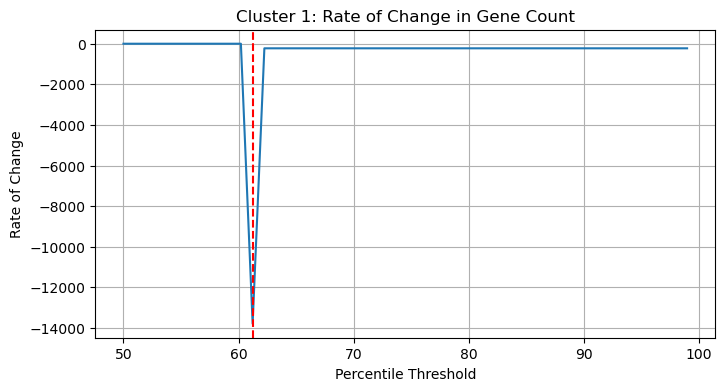


Cluster 2 critical point:
  Percentile range: 65.31 - 66.33
  Avg genes per protein: 22614.00 → 7614.92
  Drop magnitude: 14999.08
  Correlation threshold value: 0.0000


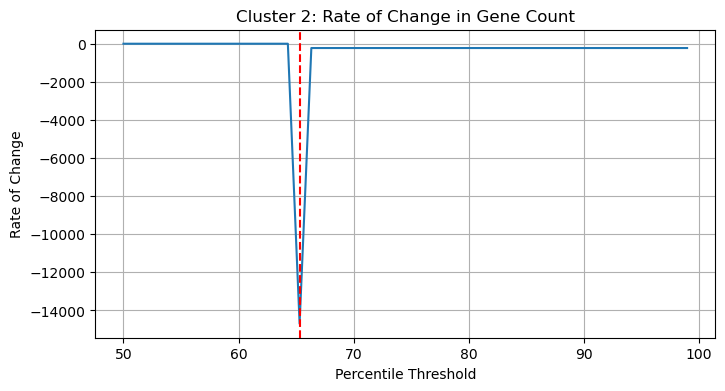

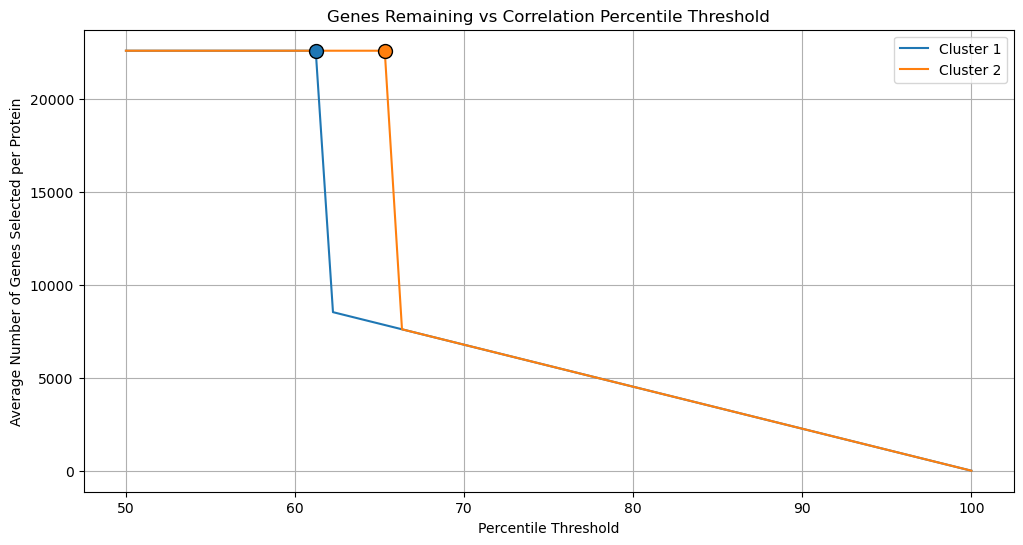

In [30]:
# --- Config ---
percentiles = np.linspace(50, 100, 50)

# Store results
thresholds = {}
gene_counts = {}

# First populate the thresholds and gene_counts dictionaries
for i, (name, df_cluster) in enumerate({"Cluster 1": df_cluster1, "Cluster 2": df_cluster2}.items()):
    vals = df_cluster.values.flatten()
    vals = vals[~np.isnan(vals)]
    
    thr_values = np.percentile(np.abs(vals), percentiles)
    thresholds[name] = thr_values
    
    counts = []
    for thr in thr_values:
        # Calculate average number of genes above threshold per protein (matching graph calculation)
        mask = (np.abs(df_cluster.values) >= thr)
        avg_genes_per_protein = mask.sum(axis=1).mean()
        counts.append(avg_genes_per_protein)
    gene_counts[name] = counts

# Now calculate critical points for each cluster
for name in thresholds.keys():
    # Calculate rate of change (derivative)
    gene_counts_array = np.array(gene_counts[name])
    derivatives = np.diff(gene_counts_array) / np.diff(percentiles)
    
    # Find the index of maximum rate of change (most negative value)
    critical_idx = np.argmin(derivatives)
    
    # Get corresponding percentile and gene counts
    critical_percentile = percentiles[critical_idx]
    critical_percentile_next = percentiles[critical_idx + 1]
    genes_at_critical = gene_counts[name][critical_idx]
    genes_at_next = gene_counts[name][critical_idx + 1]
    
    print(f"\n{name} critical point:")
    print(f"  Percentile range: {critical_percentile:.2f} - {critical_percentile_next:.2f}")
    print(f"  Avg genes per protein: {genes_at_critical:.2f} → {genes_at_next:.2f}")
    print(f"  Drop magnitude: {genes_at_critical - genes_at_next:.2f}")
    
    # Find threshold value at the critical point
    threshold_value = thresholds[name][critical_idx]
    print(f"  Correlation threshold value: {threshold_value:.4f}")
    
    # Optional: plot the derivatives to visualize the critical point
    plt.figure(figsize=(8, 4))
    plt.plot(percentiles[:-1], derivatives)
    plt.axvline(x=critical_percentile, color='r', linestyle='--')
    plt.title(f"{name}: Rate of Change in Gene Count")
    plt.xlabel("Percentile Threshold")
    plt.ylabel("Rate of Change")
    plt.grid(True)
    plt.show()

# Bonus: Plot the gene counts vs percentiles with critical points marked
plt.figure(figsize=(12, 6))
for name in thresholds.keys():
    plt.plot(percentiles, gene_counts[name], label=name)
    
    # Get critical point index and mark it on the plot
    critical_idx = np.argmin(np.diff(gene_counts[name]) / np.diff(percentiles))
    plt.scatter(percentiles[critical_idx], gene_counts[name][critical_idx], 
                marker='o', s=100, edgecolors='black', zorder=5)

plt.xlabel("Percentile Threshold")
plt.ylabel("Average Number of Genes Selected per Protein")
plt.title("Genes Remaining vs Correlation Percentile Threshold")
plt.legend()
plt.grid(True)
plt.show()

## 3 clusters

In [31]:
prot_c1 = clusters3.loc[clusters3.Cluster == 1, "Protein"]
prot_c2 = clusters3.loc[clusters3.Cluster == 2, "Protein"]
prot_c3 = clusters3.loc[clusters3.Cluster == 3, "Protein"] 

df_cluster1 = pearson.loc[pearson.index.intersection(prot_c1)]
df_cluster2 = pearson.loc[pearson.index.intersection(prot_c2)]
df_cluster3 = pearson.loc[pearson.index.intersection(prot_c3)]
# now df_cluster1 and df_cluster2 each contain only the rows
# for proteins in cluster 1 or cluster 2, respectively.

In [32]:
df_cluster1.describe()


,A1BG,A1BG-AS1,A1CF,A2M,A2ML1,A4GALT,AAAS,AACS,AACSP1,AADAC,...,ZWILCH,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11A,ZYG11B,ZYX,ZZEF1,ZZZ3
count,1696.000000,1696.000000,1696.000000,1696.000000,1696.000000,1696.000000,1696.000000,1696.000000,1696.000000,1696.000000,...,1696.000000,1696.000000,1696.000000,1696.000000,1696.000000,1696.000000,1696.000000,1696.000000,1696.000000,1696.000000
mean,0.052697,0.041527,0.001671,-0.035669,-0.056942,-0.130295,0.135283,-0.007268,0.004203,-0.051945,...,0.008123,0.046601,0.001413,0.018755,0.077743,0.007604,-0.007534,-0.129680,0.064359,0.016825
std,0.103388,0.093460,0.068581,0.068952,0.103703,0.098683,0.098201,0.058583,0.037471,0.074803,...,0.067396,0.090864,0.039743,0.052428,0.093185,0.060062,0.085200,0.110140,0.086929,0.066123
min,-0.394757,-0.419261,-0.257735,-0.305118,-0.319891,-0.388278,-0.220384,-0.250441,-0.207530,-0.264705,...,-0.259564,-0.276436,-0.197756,-0.187713,-0.147429,-0.239348,-0.371998,-0.382800,-0.192112,-0.253249
25%,0.000000,0.000000,0.000000,-0.094942,-0.149016,-0.205382,0.000000,0.000000,0.000000,-0.122120,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.211907,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,-0.144184,0.149406,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.151352,0.000000,0.000000
75%,0.137590,0.117899,0.000000,0.000000,0.000000,0.000000,0.209855,0.000000,0.000000,0.000000,...,0.000000,0.123822,0.000000,0.000000,0.160096,0.000000,0.000000,0.000000,0.142683,0.000000
max,0.331081,0.347560,0.620241,0.222556,0.239776,0.140660,0.434256,0.228584,0.172276,0.188117,...,0.282370,0.333329,0.226135,0.255212,0.419057,0.313880,0.276979,0.193424,0.386142,0.365429


In [33]:
df_cluster2.describe()

,A1BG,A1BG-AS1,A1CF,A2M,A2ML1,A4GALT,AAAS,AACS,AACSP1,AADAC,...,ZWILCH,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11A,ZYG11B,ZYX,ZZEF1,ZZZ3
count,928.000000,928.000000,928.000000,928.000000,928.000000,928.000000,928.000000,928.000000,928.000000,928.000000,...,928.000000,928.000000,928.000000,928.000000,928.000000,928.000000,928.000000,928.000000,928.000000,928.000000
mean,-0.118682,-0.096064,0.007399,0.018386,0.089836,0.178380,-0.178830,0.056000,-0.000958,0.085343,...,-0.006015,-0.032470,0.003664,-0.009275,-0.049361,-0.002536,0.029574,0.138404,-0.065654,-0.007535
std,0.130074,0.124293,0.091303,0.112214,0.097324,0.102403,0.093751,0.089557,0.025779,0.083645,...,0.068346,0.065909,0.039445,0.046245,0.089016,0.060052,0.103174,0.128201,0.080400,0.069914
min,-0.471511,-0.441072,-0.302278,-0.354596,-0.178732,0.000000,-0.431696,-0.207641,-0.154294,-0.133701,...,-0.248687,-0.233003,-0.216721,-0.194964,-0.310088,-0.221905,-0.328854,-0.277035,-0.280359,-0.287883
25%,-0.212185,-0.188180,0.000000,0.000000,0.000000,0.126608,-0.242850,0.000000,0.000000,0.000000,...,0.000000,-0.092028,0.000000,0.000000,-0.125028,0.000000,0.000000,0.000000,-0.140202,0.000000
50%,-0.119939,-0.082163,0.000000,0.000000,0.100739,0.186699,-0.190079,0.000000,0.000000,0.104250,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.155546,0.000000,0.000000
75%,0.000000,0.000000,0.000000,0.104891,0.160419,0.248764,-0.131138,0.133908,0.000000,0.148058,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.111917,0.234959,0.000000,0.000000
max,0.192086,0.223438,0.370102,0.319265,0.366103,0.462668,0.000000,0.350304,0.156792,0.350244,...,0.216541,0.221538,0.214449,0.185426,0.210642,0.208993,0.322272,0.463936,0.224382,0.247094


In [34]:
df_cluster3.describe()

,A1BG,A1BG-AS1,A1CF,A2M,A2ML1,A4GALT,AAAS,AACS,AACSP1,AADAC,...,ZWILCH,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11A,ZYG11B,ZYX,ZZEF1,ZZZ3
count,2489.000000,2489.000000,2489.000000,2489.000000,2489.000000,2489.000000,2489.000000,2489.000000,2489.000000,2489.000000,...,2489.000000,2489.000000,2489.000000,2489.000000,2489.000000,2489.000000,2489.000000,2489.000000,2489.000000,2489.000000
mean,0.010835,0.011387,-0.011714,0.025667,-0.014039,0.012656,-0.019082,-0.006685,0.000653,0.005080,...,0.007638,-0.005349,0.006116,0.005615,-0.002648,0.007508,0.022313,0.058614,-0.010551,0.019516
std,0.108352,0.104647,0.080768,0.081842,0.096385,0.082996,0.081145,0.077507,0.043925,0.067998,...,0.073857,0.089351,0.044687,0.049130,0.076772,0.069092,0.099672,0.105906,0.085059,0.068038
min,-0.335868,-0.372741,-0.325459,-0.280763,-0.282106,-0.303208,-0.302349,-0.269874,-0.207714,-0.273304,...,-0.291625,-0.292748,-0.186448,-0.210611,-0.311360,-0.330242,-0.325829,-0.270890,-0.272155,-0.235842
25%,0.000000,0.000000,0.000000,0.000000,-0.081045,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.143996,0.000000,0.000000
max,0.392804,0.409780,0.378436,0.395727,0.246083,0.340446,0.281534,0.470513,0.355469,0.242996,...,0.267605,0.270492,0.249703,0.235868,0.359242,0.357060,0.416357,0.685036,0.363437,0.286004


In [35]:

# compute the describe() tables
desc1 = df_cluster1.describe()
desc2 = df_cluster2.describe()
desc3 = df_cluster3.describe()

# pull out the "max" row and take its mean
avg_of_max1 = desc1.loc["max"].mean()
avg_of_max2 = desc2.loc["max"].mean()
avg_of_max3 = desc3.loc["max"].mean()

# print the results
print(f"Average of per‑column max correlations (Cluster 1): {avg_of_max1:.4f}")
print(f"Average of per‑column max correlations (Cluster 2): {avg_of_max2:.4f}")
print(f"Average of per‑column max correlations (Cluster 3): {avg_of_max3:.4f}")


Average of per‑column max correlations (Cluster 1): 0.2950
Average of per‑column max correlations (Cluster 2): 0.2680
Average of per‑column max correlations (Cluster 3): 0.3361


We choose this number of genes per cluster by sweeping percentile cutoffs on |r| within that cluster, producing a curve of the average genes retained per protein as the threshold tightens.
We then locate the elbow—the percentile with the steepest drop—where increasing strictness begins to discard many genes at once, signaling diminishing returns.
Selecting the |r| at this elbow preserves the strongest, most reliable correlations while avoiding over-pruning that would remove useful signal.
We convert that elbow threshold into the expected genes retained per protein and use it as the cluster’s gene count, giving a data-adaptive and comparable choice across clusters.

We start by defining two knobs: a percentile cutoff thr_pct (default 90th) that becomes a cluster-specific |r| threshold, and k_top_genes (how many “driver” genes we report). We package the three cluster matrices (df_cluster1/2/3), same gene columns, rows as proteins/samples—with entries that are typically Pearson correlations r.

We then flatten each cluster’s entries to study its correlation distribution (mean, median, SD, skewness, kurtosis, and key percentiles like 75/90/95). From these distributions, we set a cluster-specific cutoff as the thr_pct-th percentile of |r|; clusters with broader tails naturally get a higher absolute threshold, so the rule adapts to each cluster’s signal strength.

To choose how strict the cutoff should be, we run two complementary analyses. First, a coarse sweep (percentiles_to_test) prints how many genes are retained at several percentiles (corr_utils.compute_gene_retention). Second, a dense sweep (50→100%) maps percentile → average genes per protein retained (count with |r| ≥ threshold) for each cluster. We take the discrete derivative of this curve and pick the most negative slope, the elbow, where tightening the threshold suddenly removes many genes. We report that critical percentile, its |r| value, and the expected genes per protein retained, and we plot both the derivative (with the elbow) and the “genes-remaining vs percentile” curve (with the elbow marked).

In practice, we set the selection cutoff to the cluster-specific |r| at the elbow. This preserves the strongest associations while avoiding over-pruning. The corresponding average genes per protein gives a practical proxy for how many genes to keep in each cluster. Direction is ignored because we threshold |r|; it’s set that all clusters share the same gene set/order; NaNs are handled via np.nan* operations; and, if the derivative is noisy, a light smoothing on the gene-count curve can be applied so the elbow is more stable.

In [36]:
# --- Configuration ---
thr_pct = 90  # percentile for threshold selection
k_top_genes = 20  # top driver genes

# --- Prepare data ---
clusters = {
    'Cluster 1': df_cluster1,
    'Cluster 2': df_cluster2,
    'Cluster 3': df_cluster3
}

# Flatten and clean values
vals = {}
for name, df in clusters.items():
    v = df.values.flatten()
    v = v[~np.isnan(v)]
    vals[name] = v

# --- Summary Statistics ---
print("=== Summary Statistics ===")
for name, v in vals.items():
    print(f"\n{name}:")
    print(f"  Mean       = {np.mean(v):.4f}")
    print(f"  Std Dev    = {np.std(v, ddof=1):.4f}")
    print(f"  Median     = {np.median(v):.4f}")
    print(f"  Skewness   = {skew(v):.4f}")
    print(f"  Kurtosis   = {kurtosis(v):.4f}")
    for p in [75, 90, 95]:
        print(f"  {p}th pct  = {np.percentile(v, p):.4f}")

# --- Thresholds ---
print("\n=== Cluster-specific Thresholds (|r| at top {}%) ===".format(thr_pct))
thresholds = {}
for name, v in vals.items():
    thr = np.percentile(np.abs(v), thr_pct)
    thresholds[name] = thr
    print(f"{name}: {thr:.4f}")

# --- Cohesion & Separation Metrics ---
print("\n=== Cohesion, Separation, and Silhouette Scores ===")
df_all = pd.concat(list(clusters.values()))
labels = np.concatenate([[i+1]*df.shape[0] for i, df in enumerate(clusters.values())])
X = df_all.values

# Centroids
centroids = {i+1: np.nanmean(df.values, axis=0) for i, df in enumerate(clusters.values())}
global_centroid = np.nanmean(X, axis=0)

# WSS
wss = {}
for i, (name, df) in enumerate(clusters.items(), start=1):
    diffs = df.values - centroids[i]
    wss[i] = np.nansum((diffs**2).sum(axis=1))
    print(f"WSS {name}: {wss[i]:.2f}")

# BSS
bss = sum(df.shape[0] * np.sum((centroids[i+1] - global_centroid)**2) for i, df in enumerate(clusters.values()))
print(f"Between-Cluster SS (BSS): {bss:.2f}")

# Silhouette
sil_vals = silhouette_samples(X, labels, metric='euclidean')
sil_mean = silhouette_score(X, labels, metric='euclidean')
print(f"Mean Silhouette Score: {sil_mean:.4f}")
for i in range(1, 4):
    cluster_sil = sil_vals[labels == i].mean()
    print(f"Cluster {i} Silhouette: {cluster_sil:.4f}")

# --- Cluster Centroids & Top Driver Genes ---
print("\n=== Top Driver Genes per Cluster ===")
genes = df_cluster1.columns  # assuming same columns across clusters
for i in range(1, 4):
    cent = centroids[i]
    top_genes = genes[np.argsort(np.abs(cent))[-k_top_genes:]][::-1]
    print(f"\nTop {k_top_genes} genes for Cluster {i}:")
    print(top_genes.tolist())

=== Summary Statistics ===

Cluster 1:
  Mean       = 0.0073
  Std Dev    = 0.1063
  Median     = 0.0000
  Skewness   = -0.0080
  Kurtosis   = 1.4265
  75th pct  = 0.0000
  90th pct  = 0.1529
  95th pct  = 0.1948

Cluster 2:
  Mean       = -0.0037
  Std Dev    = 0.1312
  Median     = 0.0000
  Skewness   = 0.2125
  Kurtosis   = 1.1019
  75th pct  = 0.0000
  90th pct  = 0.1699
  95th pct  = 0.2293

Cluster 3:
  Mean       = 0.0031
  Std Dev    = 0.0846
  Median     = 0.0000
  Skewness   = 0.1674
  Kurtosis   = 2.6149
  75th pct  = 0.0000
  90th pct  = 0.1224
  95th pct  = 0.1610

=== Cluster-specific Thresholds (|r| at top 90%) ===
Cluster 1: 0.1889
Cluster 2: 0.2254
Cluster 3: 0.1559

=== Cohesion, Separation, and Silhouette Scores ===
WSS Cluster 1: 261167.53
WSS Cluster 2: 169235.97
WSS Cluster 3: 375466.56
Between-Cluster SS (BSS): 384000.58
Mean Silhouette Score: 0.1350
Cluster 1 Silhouette: 0.1693
Cluster 2 Silhouette: 0.1302
Cluster 3 Silhouette: 0.1135

=== Top Driver Genes per C

In [37]:
# Main analysis
# Threshold-based gene retention analysis

# --- Configuration ---
percentiles_to_test = [75, 85, 90, 95, 97]
clusters = {
    'Cluster 1': df_cluster1,
    'Cluster 2': df_cluster2,
    'Cluster 3': df_cluster3,

}
for cluster_name, df_c in clusters.items():
    print(f"\n=== {cluster_name} ===")
    thresholds, retained = corr_utils.compute_gene_retention(df_c, percentiles_to_test)
    for p in percentiles_to_test:
        print(f"Percentile {p}% (Threshold: {thresholds[p]:.4f}): {retained[p]} genes retained")



=== Cluster 1 ===
Percentile 75% (Threshold: 0.1290): 22599 genes retained
Percentile 85% (Threshold: 0.1639): 22405 genes retained
Percentile 90% (Threshold: 0.1889): 21901 genes retained
Percentile 95% (Threshold: 0.2281): 20052 genes retained
Percentile 97% (Threshold: 0.2550): 17978 genes retained

=== Cluster 2 ===
Percentile 75% (Threshold: 0.1541): 22461 genes retained
Percentile 85% (Threshold: 0.1954): 21606 genes retained
Percentile 90% (Threshold: 0.2254): 20101 genes retained
Percentile 95% (Threshold: 0.2729): 16011 genes retained
Percentile 97% (Threshold: 0.3058): 12734 genes retained

=== Cluster 3 ===
Percentile 75% (Threshold: 0.1018): 22607 genes retained
Percentile 85% (Threshold: 0.1346): 22607 genes retained
Percentile 90% (Threshold: 0.1559): 22587 genes retained
Percentile 95% (Threshold: 0.1898): 22205 genes retained
Percentile 97% (Threshold: 0.2135): 21541 genes retained



Cluster 1 critical point:
  Percentile range: 61.22 - 62.24
  Avg genes per protein: 22614.00 → 8537.94
  Drop magnitude: 14076.06
  Correlation threshold value: 0.0000


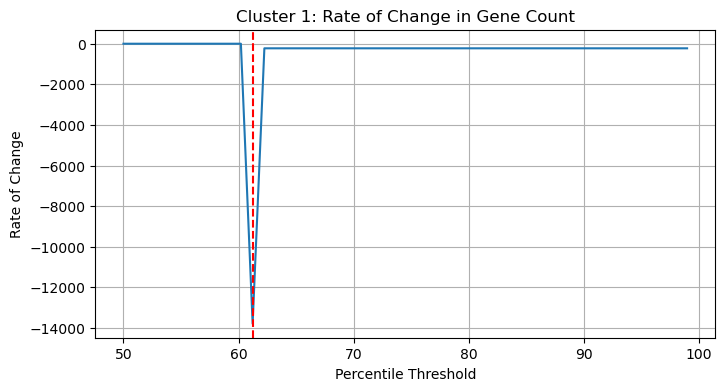


Cluster 2 critical point:
  Percentile range: 53.06 - 54.08
  Avg genes per protein: 22614.00 → 10383.98
  Drop magnitude: 12230.02
  Correlation threshold value: 0.0000


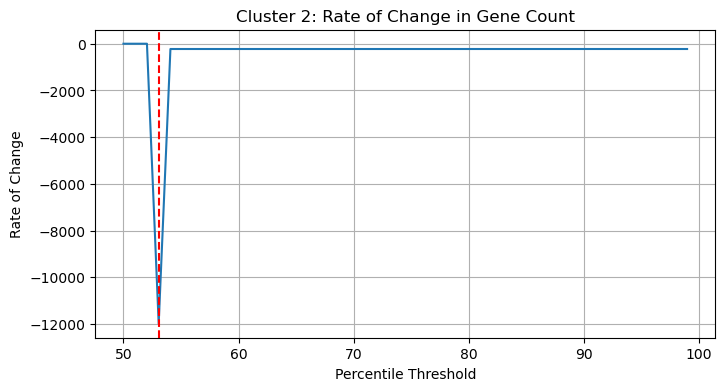


Cluster 3 critical point:
  Percentile range: 69.39 - 70.41
  Avg genes per protein: 22614.00 → 6691.90
  Drop magnitude: 15922.10
  Correlation threshold value: 0.0000


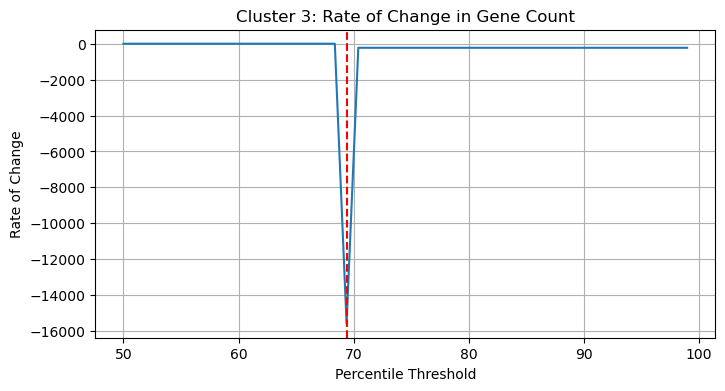

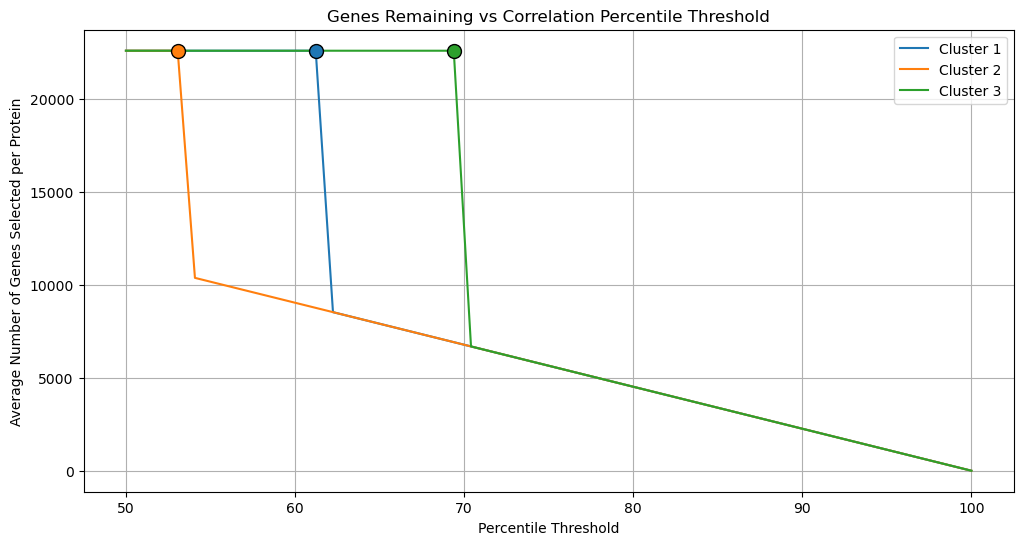

In [38]:
# --- Config ---
percentiles = np.linspace(50, 100, 50)

# Store results
thresholds = {}
gene_counts = {}

# First populate the thresholds and gene_counts dictionaries
for i, (name, df_cluster) in enumerate({"Cluster 1": df_cluster1, "Cluster 2": df_cluster2, "Cluster 3": df_cluster3}.items()):
    vals = df_cluster.values.flatten()
    vals = vals[~np.isnan(vals)]
    
    thr_values = np.percentile(np.abs(vals), percentiles)
    thresholds[name] = thr_values
    
    counts = []
    for thr in thr_values:
        # Calculate average number of genes above threshold per protein (matching graph calculation)
        mask = (np.abs(df_cluster.values) >= thr)
        avg_genes_per_protein = mask.sum(axis=1).mean()
        counts.append(avg_genes_per_protein)
    gene_counts[name] = counts

# Now calculate critical points for each cluster
for name in thresholds.keys():
    # Calculate rate of change (derivative)
    gene_counts_array = np.array(gene_counts[name])
    derivatives = np.diff(gene_counts_array) / np.diff(percentiles)
    
    # Find the index of maximum rate of change (most negative value)
    critical_idx = np.argmin(derivatives)
    
    # Get corresponding percentile and gene counts
    critical_percentile = percentiles[critical_idx]
    critical_percentile_next = percentiles[critical_idx + 1]
    genes_at_critical = gene_counts[name][critical_idx]
    genes_at_next = gene_counts[name][critical_idx + 1]
    
    print(f"\n{name} critical point:")
    print(f"  Percentile range: {critical_percentile:.2f} - {critical_percentile_next:.2f}")
    print(f"  Avg genes per protein: {genes_at_critical:.2f} → {genes_at_next:.2f}")
    print(f"  Drop magnitude: {genes_at_critical - genes_at_next:.2f}")
    
    # Find threshold value at the critical point
    threshold_value = thresholds[name][critical_idx]
    print(f"  Correlation threshold value: {threshold_value:.4f}")
    
    # Optional: plot the derivatives to visualize the critical point
    plt.figure(figsize=(8, 4))
    plt.plot(percentiles[:-1], derivatives)
    plt.axvline(x=critical_percentile, color='r', linestyle='--')
    plt.title(f"{name}: Rate of Change in Gene Count")
    plt.xlabel("Percentile Threshold")
    plt.ylabel("Rate of Change")
    plt.grid(True)
    plt.show()

# Bonus: Plot the gene counts vs percentiles with critical points marked
plt.figure(figsize=(12, 6))
for name in thresholds.keys():
    plt.plot(percentiles, gene_counts[name], label=name)
    
    # Get critical point index and mark it on the plot
    critical_idx = np.argmin(np.diff(gene_counts[name]) / np.diff(percentiles))
    plt.scatter(percentiles[critical_idx], gene_counts[name][critical_idx], 
                marker='o', s=100, edgecolors='black', zorder=5)

plt.xlabel("Percentile Threshold")
plt.ylabel("Average Number of Genes Selected per Protein")
plt.title("Genes Remaining vs Correlation Percentile Threshold")
plt.legend()
plt.grid(True)
plt.show()